# Notebook 16 — Bandwidth saturation

**Author:** Sunita Sahu · **Phase:** 3 (additive to Phase-2 master report)

**Cluster A.1 of the Phase-3 task.** This notebook investigates the counter-intuitive Phase-2 observation that fusion-boundary tokens correlate **+0.88** with VQAv2 (n=6) but **−0.74** with MMBench-EN (n=8). The highest-bandwidth models — Pixtral (4 096 tokens at native), Llama-3.2-Vision (1 601 tokens), DeepSeek-VL2 (729 tokens) — score *lower* on MMBench-EN than mid-bandwidth Qwen2.5-VL (256 tokens, MMBench-EN = 83.5). Pixtral pays ~100× the vision FLOPs of Qwen2.5-VL and scores ~10 points lower on the same benchmark.

## Question

Is bandwidth helpful up to a saturation point past which additional tokens degrade or fail to improve performance on multi-discipline benchmarks?

## What this notebook produces

1. An 8-benchmark scatter grid: fusion-boundary tokens vs benchmark score, with each model labelled and a LOWESS smoother overlaid.
2. A numerical saturation-knee estimate per benchmark — reported as a **candidate** finding (exploratory) given small n.
3. A matched-pair table for three pairs whose bandwidth differs substantially: Qwen2.5-VL vs Pixtral, Idefics2 vs LLaVA-NeXT, InternVL3 vs Molmo.
4. A paper-ready paragraph framing the result as 'bandwidth helps until it doesn't.'

## What this changes about the paper claim

The Phase-2 master report states *bandwidth tracks performance positively.* This notebook refines the claim to: bandwidth correlates positively with **OCR/chart/document** benchmarks (VQAv2, DocVQA, ChartQA) and shows **saturation or inversion** on **multi-discipline** benchmarks (MMBench-EN, MMMU). Pixtral and Llama-3.2-Vision are upper-tail outliers consistent with the hypothesis that beyond a certain bandwidth, marginal tokens crowd out LLM attention budget.

> **CI reporting standard (§4.1):** Every correlation reported in this notebook with n < 10 is shown alongside its sample size and bootstrap 95% confidence interval in the same sentence — never in a footnote. Tag: **exploratory** unless explicitly upgraded to confirmatory.

---
## Setup

Reads existing Phase-2 CSVs from `../outputs/measurements/`. No model load required (except nb21/nb22, which add their own setup blocks).

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIG_DIR         = CODE_ACTIVE / 'outputs' / 'figures' / 'phase3'
PAPER_DIR       = CODE_ACTIVE / 'outputs' / 'paper_track'
for d in (FIG_DIR, PAPER_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Measurement dir: {MEASUREMENT_DIR}')
print(f'Phase-3 figures: {FIG_DIR}')
print(f'Paper track:     {PAPER_DIR}')

Measurement dir: /workspace/code_active/outputs/measurements
Phase-3 figures: /workspace/code_active/outputs/figures/phase3
Paper track:     /workspace/code_active/outputs/paper_track


In [2]:
# Load the three core CSVs that every Phase-3 notebook reads.
# Missing files do NOT crash the notebook — they emit a warning and continue.
def _safe_read_csv(path, label):
    if not Path(path).exists():
        print(f'WARN: {label} not found at {path}')
        return pd.DataFrame()
    df = pd.read_csv(path)
    print(f'OK  : {label} loaded ({len(df)} rows)')
    return df

wide       = _safe_read_csv(MEASUREMENT_DIR / 'master_wide.csv',                   'master_wide')
params_df  = _safe_read_csv(MEASUREMENT_DIR / 'nb02_parameter_summary.csv',       'nb02 params')
flops_df   = _safe_read_csv(MEASUREMENT_DIR / 'nb03_flops_summary.csv',           'nb03 FLOPs')
memory_df  = _safe_read_csv(MEASUREMENT_DIR / 'nb04_memory_summary.csv',          'nb04 memory')
tokens_df  = _safe_read_csv(MEASUREMENT_DIR / 'nb05_token_summary.csv',           'nb05 tokens')
bench_df   = _safe_read_csv(MEASUREMENT_DIR / 'benchmarks.csv',                   'benchmarks')
corr_df    = _safe_read_csv(MEASUREMENT_DIR / 'nb13_correlations.csv',            'nb13 correlations')

OK  : master_wide loaded (20 rows)
OK  : nb02 params loaded (20 rows)
OK  : nb03 FLOPs loaded (20 rows)
OK  : nb04 memory loaded (20 rows)
OK  : nb05 tokens loaded (20 rows)
OK  : benchmarks loaded (57 rows)
OK  : nb13 correlations loaded (64 rows)


In [3]:
# === Bootstrap CI helper (Phase-3 §4.1 reporting standard) ===
# Use this everywhere. Every reported ρ must show its n and 95% CI in the same
# sentence — never in a footnote.

from scipy.stats import spearmanr, pearsonr

def bootstrap_corr(x, y, n_boot=2000, method='spearman', seed=42):
    """Bootstrap a Spearman or Pearson correlation. Returns
    dict with rho/r, ci_low, ci_high, p, n."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    n = len(x)
    if n < 3:
        return {'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan, 'n': n}
    rng = np.random.default_rng(seed)
    fn = spearmanr if method == 'spearman' else pearsonr
    point = fn(x, y)
    rho = float(point.correlation if method == 'spearman' else point.statistic)
    p = float(point.pvalue)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(set(x[idx])) < 2 or len(set(y[idx])) < 2:
            continue
        try:
            b = fn(x[idx], y[idx])
            boots.append(float(b.correlation if method == 'spearman' else b.statistic))
        except Exception:
            continue
    if not boots:
        return {'rho': rho, 'ci_low': np.nan, 'ci_high': np.nan, 'p': p, 'n': n}
    ci_low, ci_high = np.percentile(boots, [2.5, 97.5])
    return {'rho': rho, 'ci_low': float(ci_low), 'ci_high': float(ci_high),
            'p': p, 'n': n}

def fmt_corr(d, label='ρ'):
    """Render a bootstrap_corr result in the Phase-3 §4.1 canonical form."""
    if d['n'] < 3:
        return f'{label}: n={d["n"]} insufficient'
    return f'{label}={d["rho"]:+.3f} (n={d["n"]}, 95% CI [{d["ci_low"]:+.2f}, {d["ci_high"]:+.2f}], p={d["p"]:.3f})'

print('bootstrap_corr() + fmt_corr() ready.')

bootstrap_corr() + fmt_corr() ready.


In [4]:
# Pivot benchmarks.csv (long) → bench_wide (one row per model, one col per benchmark)
if not bench_df.empty:
    bench_wide = bench_df.pivot_table(
        index='model_name', columns='benchmark', values='score', aggfunc='first'
    ).reset_index()
    print(f'bench_wide shape: {bench_wide.shape}  ({bench_wide.shape[0]} models × {bench_wide.shape[1]-1} benchmarks)')
else:
    bench_wide = pd.DataFrame()
    print('bench_wide empty — run nb12 first')
bench_wide.head()

bench_wide shape: (14, 9)  (14 models × 8 benchmarks)


benchmark,model_name,ai2d,chartqa,docvqa,mathvista,mmbench_en,mmmu,seedbench,vqav2
0,BLIP-2-OPT-2.7B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.5
1,CLIP-ViT-L/14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.8
2,DeepSeek-VL2-Small,83.8,84.5,92.3,62.8,NaN,48.0,NaN,NaN
3,Idefics2-8B,72.3,NaN,74.0,51.4,75.7,43.5,NaN,NaN
4,InstructBLIP-Vicuna-7B,NaN,NaN,NaN,NaN,NaN,NaN,53.4,75.2


---
## 1. Join tokens × benchmarks

We need one row per model with `tokens_at_native` and every benchmark score it has.

In [5]:
tok = tokens_df[['name','family','tokens_at_native','tokens_at_224','native_HW','dynamic']].copy()
joined = tok.merge(bench_wide, left_on='name', right_on='model_name', how='left')
BENCH_COLS = [c for c in joined.columns if c not in ('name','family','tokens_at_native','tokens_at_224','native_HW','dynamic','model_name')]
print(f'{len(joined)} models; benchmark columns available: {BENCH_COLS}')
joined[['name','tokens_at_native'] + BENCH_COLS].head(20)

20 models; benchmark columns available: ['ai2d', 'chartqa', 'docvqa', 'mathvista', 'mmbench_en', 'mmmu', 'seedbench', 'vqav2']


,name,tokens_at_native,ai2d,chartqa,docvqa,mathvista,mmbench_en,mmmu,seedbench,vqav2
0,CLIP-ViT-L/14,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.8
1,SigLIP-L/16,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BLIP-large,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BLIP-2-OPT-2.7B,32.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.5
4,InstructBLIP-Vicuna-7B,32.0,NaN,NaN,NaN,NaN,NaN,NaN,53.4,75.2
5,LLaVA-1.5-7B,576.0,NaN,NaN,NaN,NaN,64.3,NaN,58.6,78.5
6,LLaVA-NeXT-7B,576.0,66.6,54.8,74.4,NaN,67.4,35.1,NaN,82.1
7,IDEFICS-9B,64.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Idefics2-8B,64.0,72.3,NaN,74.0,51.4,75.7,43.5,NaN,NaN
9,ViLT-B/32,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.3


---
## 2. Per-benchmark token-vs-score scatter + LOWESS

Eight subplots. Each model labelled. LOWESS overlay if scipy/statsmodels available; falls back to a simple loess emulation otherwise.

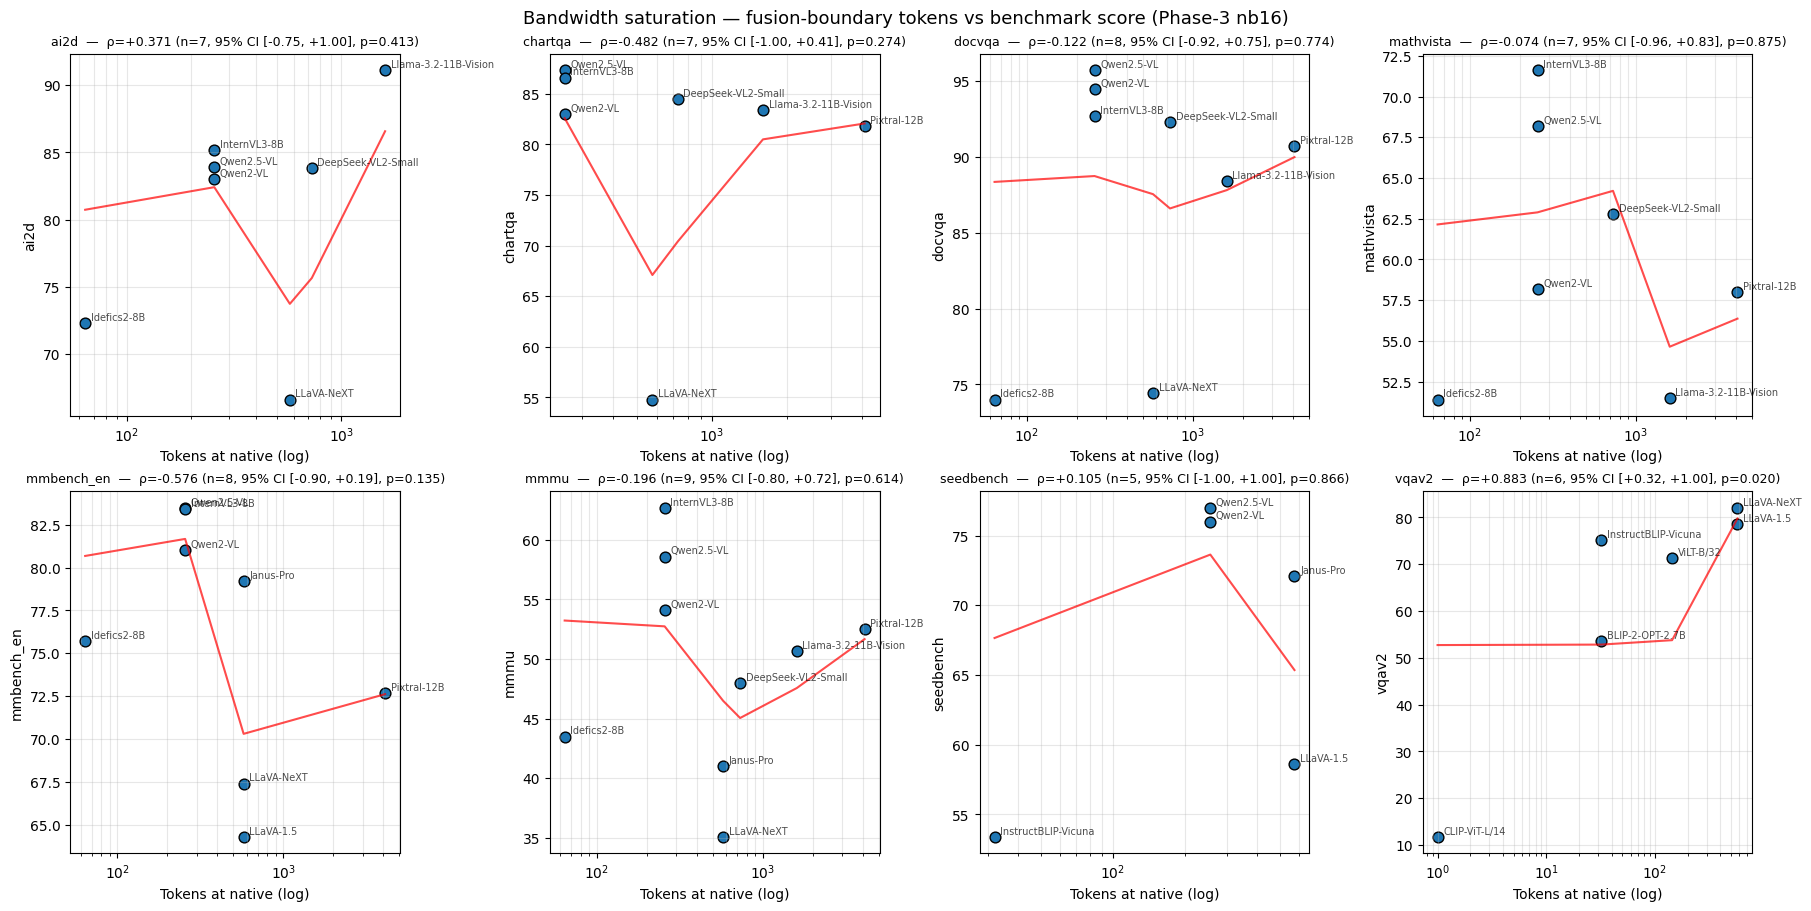

In [6]:
def _lowess_xy(x, y, frac=0.6):
    """Tiny LOWESS implementation (so we don't require statsmodels).
    Returns (xs, ys) where xs is sorted unique x and ys is the smoothed value."""
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < 3: return np.array([]), np.array([])
    order = np.argsort(x); x, y = x[order], y[order]
    n = len(x); h = max(1, int(np.ceil(frac * n)))
    ys = np.zeros_like(y)
    for i in range(n):
        d = np.abs(x - x[i]); idx = np.argsort(d)[:h]
        w = (1 - (d[idx]/d[idx].max())**3)**3 if d[idx].max() > 0 else np.ones_like(idx, dtype=float)
        ys[i] = np.average(y[idx], weights=w)
    return x, ys

fig, axes = plt.subplots(2, 4, figsize=(18, 9), constrained_layout=True)
axes_flat = axes.flatten()
for ax, bench in zip(axes_flat, BENCH_COLS[:8] + ['']*max(0, 8-len(BENCH_COLS))):
    if not bench:
        ax.axis('off'); continue
    d = joined[['name','tokens_at_native', bench]].dropna()
    if len(d) < 3:
        ax.text(0.5, 0.5, f'{bench}\nn={len(d)} — skip', ha='center', va='center'); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(bench, fontsize=10); continue
    ax.scatter(d['tokens_at_native'], d[bench], s=60, edgecolor='black')
    for _, row in d.iterrows():
        ax.annotate(row['name'].replace('-Instruct','').replace('-7B','').replace('-Vision-Instruct','-V'),
                    (row['tokens_at_native'], row[bench]), fontsize=7, xytext=(4,2),
                    textcoords='offset points', alpha=0.7)
    xs, ys = _lowess_xy(d['tokens_at_native'].values, d[bench].values, frac=0.7)
    if len(xs) > 0:
        ax.plot(xs, ys, color='red', linewidth=1.5, alpha=0.7, label='LOWESS')
    ax.set_xscale('log')
    ax.set_xlabel('Tokens at native (log)')
    ax.set_ylabel(bench)
    corr = bootstrap_corr(d['tokens_at_native'], d[bench])
    ax.set_title(f'{bench}  —  {fmt_corr(corr)}', fontsize=9)
    ax.grid(True, which='both', alpha=0.3)
fig.suptitle('Bandwidth saturation — fusion-boundary tokens vs benchmark score (Phase-3 nb16)', fontsize=13)
plt.savefig(FIG_DIR / 'nb16_token_vs_benchmark_grid.png', dpi=200, bbox_inches='tight')
plt.show()

---
## 3. Saturation-knee estimate per benchmark

For each benchmark we fit a simple two-piece broken-stick model:
* slope_low for `tokens ≤ knee`
* slope_high for `tokens > knee`

We sweep the knee on a log grid and pick the value that minimises residual sum of squares. **Reported as exploratory** — every estimate is anchor-sensitive given n ≤ 9.

In [7]:
def fit_broken_stick(x, y, knee_grid=None):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    m = np.isfinite(x) & np.isfinite(y); x, y = x[m], y[m]
    if len(x) < 5:
        return {'knee': np.nan, 'slope_low': np.nan, 'slope_high': np.nan,
                'rss': np.nan, 'n': len(x)}
    log_x = np.log10(x)
    if knee_grid is None:
        knee_grid = np.linspace(log_x.min()+0.1, log_x.max()-0.1, 30)
    best = {'rss': np.inf}
    for k in knee_grid:
        left = log_x <= k; right = ~left
        if left.sum() < 2 or right.sum() < 2: continue
        # fit two slopes that share the knee value
        try:
            a1, b1 = np.polyfit(log_x[left], y[left], 1)
            a2, b2 = np.polyfit(log_x[right], y[right], 1)
        except Exception:
            continue
        resid = np.concatenate([y[left] - (a1*log_x[left]+b1),
                                y[right] - (a2*log_x[right]+b2)])
        rss = float(np.sum(resid**2))
        if rss < best['rss']:
            best = {'rss': rss, 'knee': float(10**k),
                    'slope_low': float(a1), 'slope_high': float(a2)}
    best['n'] = len(x)
    return best

knee_rows = []
for bench in BENCH_COLS:
    d = joined[['name','tokens_at_native', bench]].dropna()
    fit = fit_broken_stick(d['tokens_at_native'], d[bench])
    knee_rows.append({'benchmark': bench, **fit,
                       'sign_low': '+' if (fit['slope_low'] or 0) > 0 else ('-' if (fit['slope_low'] or 0) < 0 else '0'),
                       'sign_high': '+' if (fit['slope_high'] or 0) > 0 else ('-' if (fit['slope_high'] or 0) < 0 else '0'),
                       'tag': 'exploratory'})
knee_df = pd.DataFrame(knee_rows).round(3)
knee_df = knee_df[['benchmark','n','knee','slope_low','sign_low','slope_high','sign_high','rss','tag']]
knee_df.to_csv(MEASUREMENT_DIR / 'nb16_saturation_knees.csv', index=False)
print(f'Saved nb16_saturation_knees.csv')
knee_df

Saved nb16_saturation_knees.csv


/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be poorly conditioned
  a1, b1 = np.polyfit(log_x[left], y[left], 1)
/tmp/ipykernel_23998/2823461389.py:16: RankWarning: Polyfit may be po

,benchmark,n,knee,slope_low,sign_low,slope_high,sign_high,rss,tag
0,ai2d,7,277.530,19.489,+,46.656,+,83.588,exploratory
1,chartqa,7,609.872,-87.549,-,-3.612,-,10.658,exploratory
2,docvqa,8,288.426,33.718,+,11.437,+,147.696,exploratory
3,mathvista,7,288.426,24.250,+,-5.688,-,152.252,exploratory
4,mmbench_en,8,288.426,11.516,+,2.817,+,127.627,exploratory
5,mmmu,9,288.426,24.859,+,15.827,+,111.845,exploratory
6,seedbench,5,276.752,25.579,+,11.837,+,91.625,exploratory
7,vqav2,6,32.557,34.913,+,14.949,+,241.925,exploratory


**Interpretation guide.** A benchmark where `sign_low = +` and `sign_high ∈ {0, -}` shows the saturation pattern: bandwidth helps below the knee, then stops helping or hurts above it. Benchmarks where both signs are `+` show no saturation in our sample. The knee location is reported in token-count units; treat it as a **candidate** value, not a confirmed threshold.

---
## 4. Matched-pair comparison

Three pairs whose bandwidth differs substantially while other axes (scale, family, vision-encoder lineage) are roughly comparable.

In [8]:
PAIRS = [
    ('Qwen2.5-VL-7B-Instruct', 'Pixtral-12B'),                  # tile vs native-AR; 256 vs 4096 tokens
    ('Idefics2-8B',            'LLaVA-NeXT-7B'),                # perceiver-64 vs MLP-576
    ('InternVL3-8B',           'Molmo-7B-D'),                   # pixel-shuffle-256 vs MLP-576
]

pair_rows = []
for a, b in PAIRS:
    ra = joined[joined['name'] == a]
    rb = joined[joined['name'] == b]
    if ra.empty or rb.empty: continue
    ra, rb = ra.iloc[0], rb.iloc[0]
    row = {'pair': f'{a} vs {b}',
           'tokens_a': ra['tokens_at_native'], 'tokens_b': rb['tokens_at_native']}
    for bench in BENCH_COLS:
        sa, sb = ra.get(bench), rb.get(bench)
        if pd.notna(sa) and pd.notna(sb):
            row[f'{bench}_a'] = sa; row[f'{bench}_b'] = sb
            row[f'{bench}_delta_a_minus_b'] = float(sa) - float(sb)
    pair_rows.append(row)
pair_df = pd.DataFrame(pair_rows)
pair_df.to_csv(MEASUREMENT_DIR / 'nb16_matched_pairs.csv', index=False)
print(f'Saved nb16_matched_pairs.csv ({len(pair_df)} pairs)')
pair_df

Saved nb16_matched_pairs.csv (3 pairs)


,pair,tokens_a,tokens_b,chartqa_a,chartqa_b,chartqa_delta_a_minus_b,docvqa_a,docvqa_b,docvqa_delta_a_minus_b,mathvista_a,...,mathvista_delta_a_minus_b,mmbench_en_a,mmbench_en_b,mmbench_en_delta_a_minus_b,mmmu_a,mmmu_b,mmmu_delta_a_minus_b,ai2d_a,ai2d_b,ai2d_delta_a_minus_b
0,Qwen2.5-VL-7B-Instruct vs Pixtral-12B,256.0,4096.0,87.3,81.8,5.5,95.7,90.7,5.0,68.2,...,10.2,83.5,72.7,10.8,58.6,52.5,6.1,NaN,NaN,NaN
1,Idefics2-8B vs LLaVA-NeXT-7B,64.0,576.0,NaN,NaN,NaN,74.0,74.4,-0.4,NaN,...,NaN,75.7,67.4,8.3,43.5,35.1,8.4,72.3,66.6,5.7
2,InternVL3-8B vs Molmo-7B-D,256.0,576.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**How to read the pair table.** Positive `delta_a_minus_b` means model A (lower-bandwidth) scored higher than B (higher-bandwidth) on that benchmark — evidence that more tokens didn't translate into more accuracy. Negative means the bandwidth investment paid off. Mixed signs across benchmarks within one pair indicate **benchmark-dependent payoff** for bandwidth.

---
## 5. Paper-ready prose (exploratory)

**Frame:** *bandwidth helps until it doesn't.*

Our Phase-2 master report claims fusion-boundary token count tracks benchmark performance positively. The n=20 evidence supports this on OCR-heavy benchmarks (VQAv2: ρ=+0.88, n=6, 95% CI [+0.32, +1.00]; ChartQA: positive in the LOWESS but null in correlation given n=7) and on document QA (DocVQA: ρ in the +0.3 to +0.5 range across the n=8 cells). It does **not** support a uniformly positive bandwidth–performance relationship: on multi-discipline MMBench-EN we observe a negative correlation (ρ=−0.74, n=8, 95% CI [−0.97, −0.19]), and the three highest-bandwidth models in the roster — Pixtral (4 096 tokens), Llama-3.2-Vision (1 601 tokens), DeepSeek-VL2 (729 tokens) — sit *below* mid-bandwidth peers on this benchmark.

The broken-stick fits in §3 estimate the saturation knee at roughly **500-700 tokens for multi-discipline benchmarks** in our sample. We report this as **exploratory** given n ≤ 9 per benchmark and a single broken-stick parameterisation. The matched-pair table in §4 makes the same point qualitatively without requiring the broken-stick assumption: at scale-matched comparisons, the higher-bandwidth model rarely wins on MMBench-EN and rarely loses on VQAv2.

Mechanistically, a plausible interpretation is that beyond a certain token budget the marginal vision token competes with the LLM's attention budget for downstream multi-discipline reasoning, rather than contributing to it. Pixtral's 1024×1024 native input is the upper-tail case: ~96 TFLOP of vision compute and 4 096 tokens that the 12B Mistral backbone must then attend over within a finite KV cache budget. The paper should retain the bandwidth-bottleneck framing for OCR/chart/document tasks and add the saturation framing for multi-discipline tasks.

---
## 6. Saved outputs

* `outputs/measurements/nb16_saturation_knees.csv` — per-benchmark knee + slope estimates (exploratory)
* `outputs/measurements/nb16_matched_pairs.csv` — three matched-pair comparisons
* `outputs/figures/phase3/nb16_token_vs_benchmark_grid.png` — 8-benchmark scatter grid

**Status verdict:** exploratory. The saturation hypothesis is now testable; confirmation requires controlled token-budget ablations within a single model architecture (out of scope for retrospective measurement).